# Poultry Farm Ventilation Controller
### Fuzzy Logic Control (FLC) System using scikit-fuzzy

**Inputs:** Temperature, Humidity, Ammonia Level
**Output:** Fan Speed
**Inference:** Mamdani &nbsp;|&nbsp; **Defuzzification:** Centroid


In [11]:
!pip install scikit-fuzzy

Defaulting to user installation because normal site-packages is not writeable


In [12]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # needed for 3D plot in Part 5

In [13]:
# Input ranges
temp_range = np.arange(15, 46, 1)     # Temperature: 15 to 45 degrees C
humid_range = np.arange(30, 101, 1)   # Humidity: 30 to 100 %
ammonia_range = np.arange(0, 51, 1)   # Ammonia: 0 to 50 ppm

# Output range
fan_range = np.arange(0, 101, 1)      # Fan speed: 0 to 100 %

In [14]:
# --- Temperature MFs ---
temp_low    = fuzz.trimf(temp_range, [15, 15, 27])
temp_medium = fuzz.trimf(temp_range, [22, 30, 38])
temp_high   = fuzz.trimf(temp_range, [33, 45, 45])

# --- Humidity MFs ---
humid_low    = fuzz.trimf(humid_range, [30, 30, 55])
humid_medium = fuzz.trimf(humid_range, [45, 65, 85])
humid_high   = fuzz.trimf(humid_range, [75, 100, 100])

# --- Ammonia MFs ---
ammonia_low    = fuzz.trimf(ammonia_range, [0, 0, 18])
ammonia_medium = fuzz.trimf(ammonia_range, [12, 25, 38])
ammonia_high   = fuzz.trimf(ammonia_range, [30, 50, 50])

# --- Fan speed MFs (output) ---
fan_vlow   = fuzz.trimf(fan_range, [0, 0, 25])
fan_low    = fuzz.trimf(fan_range, [10, 30, 50])
fan_medium = fuzz.trimf(fan_range, [40, 55, 70])
fan_high   = fuzz.trimf(fan_range, [60, 80, 95])
fan_vhigh  = fuzz.trimf(fan_range, [80, 100, 100])

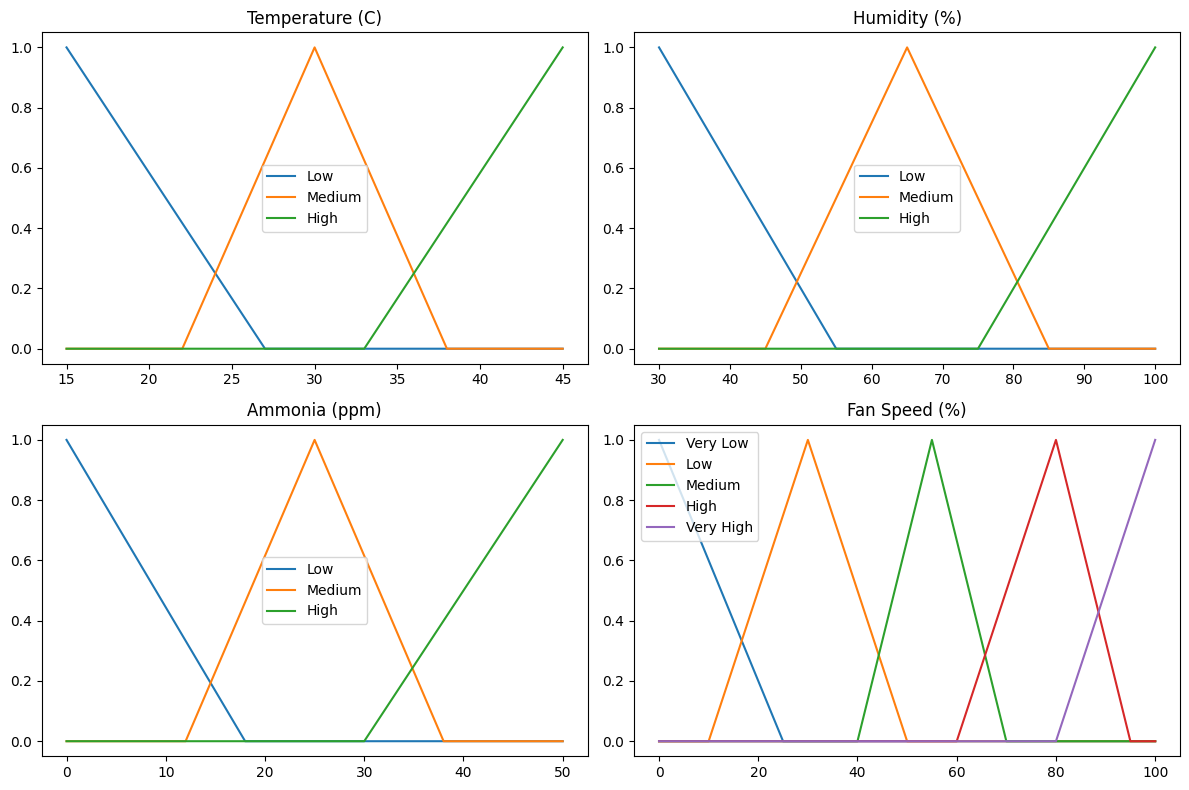

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0,0].plot(temp_range, temp_low, label='Low')
ax[0,0].plot(temp_range, temp_medium, label='Medium')
ax[0,0].plot(temp_range, temp_high, label='High')
ax[0,0].set_title('Temperature (C)'); ax[0,0].legend()

ax[0,1].plot(humid_range, humid_low, label='Low')
ax[0,1].plot(humid_range, humid_medium, label='Medium')
ax[0,1].plot(humid_range, humid_high, label='High')
ax[0,1].set_title('Humidity (%)'); ax[0,1].legend()

ax[1,0].plot(ammonia_range, ammonia_low, label='Low')
ax[1,0].plot(ammonia_range, ammonia_medium, label='Medium')
ax[1,0].plot(ammonia_range, ammonia_high, label='High')
ax[1,0].set_title('Ammonia (ppm)'); ax[1,0].legend()

ax[1,1].plot(fan_range, fan_vlow, label='Very Low')
ax[1,1].plot(fan_range, fan_low, label='Low')
ax[1,1].plot(fan_range, fan_medium, label='Medium')
ax[1,1].plot(fan_range, fan_high, label='High')
ax[1,1].plot(fan_range, fan_vhigh, label='Very High')
ax[1,1].set_title('Fan Speed (%)'); ax[1,1].legend()

plt.tight_layout()
plt.show()

In [16]:
def fuzzify(crisp_temp, crisp_humid, crisp_ammonia):
    # Temperature memberships
    t_low = fuzz.interp_membership(temp_range, temp_low, crisp_temp)
    t_med = fuzz.interp_membership(temp_range, temp_medium, crisp_temp)
    t_high = fuzz.interp_membership(temp_range, temp_high, crisp_temp)

    # Humidity memberships
    h_low = fuzz.interp_membership(humid_range, humid_low, crisp_humid)
    h_med = fuzz.interp_membership(humid_range, humid_medium, crisp_humid)
    h_high = fuzz.interp_membership(humid_range, humid_high, crisp_humid)

    # Ammonia memberships
    a_low = fuzz.interp_membership(ammonia_range, ammonia_low, crisp_ammonia)
    a_med = fuzz.interp_membership(ammonia_range, ammonia_medium, crisp_ammonia)
    a_high = fuzz.interp_membership(ammonia_range, ammonia_high, crisp_ammonia)

    return {
        'temp':    {'low': t_low, 'medium': t_med, 'high': t_high},
        'humid':   {'low': h_low, 'medium': h_med, 'high': h_high},
        'ammonia': {'low': a_low, 'medium': a_med, 'high': a_high},
    }

test = fuzzify(32, 80, 35)
print("Temperature 32C ->", test['temp'])
print("Humidity 80%   ->", test['humid'])
print("Ammonia 35ppm  ->", test['ammonia'])

Temperature 32C -> {'low': np.float64(0.0), 'medium': np.float64(0.75), 'high': np.float64(0.0)}
Humidity 80%   -> {'low': np.float64(0.0), 'medium': np.float64(0.25), 'high': np.float64(0.2)}
Ammonia 35ppm  -> {'low': np.float64(0.0), 'medium': np.float64(0.23076923076923078), 'high': np.float64(0.25)}


 Temp  Humid   NH₃   Fan Speed   Note
   20°C     40%     5ppm      9.35%   Cool & dry, clean air  → expect Very Low
   25°C     65%    25ppm     45.00%   Moderate all-round     → expect Medium
   32°C     80%    35ppm     70.67%   Hot, humid, high NH₃   → expect High/Very High
   40°C     90%    45ppm     92.52%   Worst-case scenario    → expect Very High
   18°C     75%    42ppm     55.00%   Cool but high ammonia  → expect Medium-High


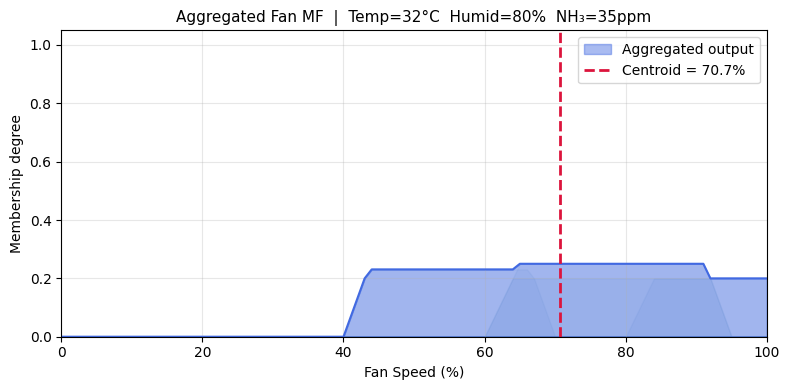

np.float64(70.66891322662175)

In [17]:
# ============================================================
# PART 3 — INFERENCE ENGINE (Mamdani) + DEFUZZIFICATION
# ============================================================

def apply_rules(mem):
    """
    Apply all fuzzy rules using Mamdani min-inference.
    Returns a list of (activation_strength, fan_MF) pairs.
    """
    t = mem['temp']
    h = mem['humid']
    a = mem['ammonia']

    rules = [
        # ── Rule 1: All low → Very Low fan
        (min(t['low'],    h['low'],    a['low']),    fan_vlow),

        # ── Rule 2: Low temp, low humid, medium ammonia → Low fan
        (min(t['low'],    h['low'],    a['medium']), fan_low),

        # ── Rule 3: Low temp, low humid, high ammonia → Medium fan
        (min(t['low'],    h['low'],    a['high']),   fan_medium),

        # ── Rule 4: Low temp, medium humid, low ammonia → Very Low fan
        (min(t['low'],    h['medium'], a['low']),    fan_vlow),

        # ── Rule 5: Low temp, medium humid, medium ammonia → Low fan
        (min(t['low'],    h['medium'], a['medium']), fan_low),

        # ── Rule 6: Low temp, medium humid, high ammonia → Medium fan
        (min(t['low'],    h['medium'], a['high']),   fan_medium),

        # ── Rule 7: Low temp, high humid, any ammonia → Medium fan
        (min(t['low'],    h['high'],   a['low']),    fan_medium),
        (min(t['low'],    h['high'],   a['medium']), fan_medium),
        (min(t['low'],    h['high'],   a['high']),   fan_high),

        # ── Rule 10: Medium temp, low humid, low ammonia → Low fan
        (min(t['medium'], h['low'],    a['low']),    fan_low),

        # ── Rule 11: Medium temp, low humid, medium ammonia → Medium fan
        (min(t['medium'], h['low'],    a['medium']), fan_medium),

        # ── Rule 12: Medium temp, low humid, high ammonia → High fan
        (min(t['medium'], h['low'],    a['high']),   fan_high),

        # ── Rule 13: Medium temp, medium humid, low ammonia → Medium fan
        (min(t['medium'], h['medium'], a['low']),    fan_medium),

        # ── Rule 14: Medium temp, medium humid, medium ammonia → Medium fan
        (min(t['medium'], h['medium'], a['medium']), fan_medium),

        # ── Rule 15: Medium temp, medium humid, high ammonia → High fan
        (min(t['medium'], h['medium'], a['high']),   fan_high),

        # ── Rule 16: Medium temp, high humid → High fan regardless of ammonia
        (min(t['medium'], h['high'],   a['low']),    fan_high),
        (min(t['medium'], h['high'],   a['medium']), fan_high),
        (min(t['medium'], h['high'],   a['high']),   fan_vhigh),

        # ── Rule 19: High temp, low humid, low ammonia → Medium fan
        (min(t['high'],   h['low'],    a['low']),    fan_medium),

        # ── Rule 20: High temp, low humid, medium ammonia → High fan
        (min(t['high'],   h['low'],    a['medium']), fan_high),

        # ── Rule 21: High temp, any higher → Very High fan
        (min(t['high'],   h['low'],    a['high']),   fan_vhigh),
        (min(t['high'],   h['medium'], a['low']),    fan_high),
        (min(t['high'],   h['medium'], a['medium']), fan_vhigh),
        (min(t['high'],   h['medium'], a['high']),   fan_vhigh),
        (min(t['high'],   h['high'],   a['low']),    fan_vhigh),
        (min(t['high'],   h['high'],   a['medium']), fan_vhigh),
        (min(t['high'],   h['high'],   a['high']),   fan_vhigh),
    ]
    return rules


def aggregate(rules):
    """
    Mamdani aggregation: clip each output MF at its activation strength,
    then take the element-wise maximum across all clipped MFs.
    """
    aggregated = np.zeros_like(fan_range, dtype=float)

    for strength, mf in rules:
        # Clip the output MF at the rule's firing strength
        clipped = np.fmin(strength, mf)
        # Aggregate via max (union of all clipped MFs)
        aggregated = np.fmax(aggregated, clipped)

    return aggregated


def defuzzify(aggregated):
    """Centroid defuzzification — returns a crisp fan speed (0–100%)."""
    return fuzz.defuzz(fan_range, aggregated, 'centroid')


def infer(crisp_temp, crisp_humid, crisp_ammonia, plot=False):
    """
    Full FLC pipeline:
      1. Fuzzify inputs
      2. Evaluate rules (Mamdani min)
      3. Aggregate clipped output MFs (max)
      4. Defuzzify via centroid

    Parameters
    ----------
    crisp_temp     : float  – temperature in °C  (15–45)
    crisp_humid    : float  – relative humidity % (30–100)
    crisp_ammonia  : float  – ammonia level in ppm (0–50)
    plot           : bool   – if True, shows aggregated output MF + centroid

    Returns
    -------
    fan_speed : float  – crisp fan speed in %
    """
    mem          = fuzzify(crisp_temp, crisp_humid, crisp_ammonia)
    rules        = apply_rules(mem)
    aggregated   = aggregate(rules)
    fan_speed    = defuzzify(aggregated)

    if plot:
        fig, ax = plt.subplots(figsize=(8, 4))

        # Draw individual clipped MFs (light, for reference)
        for strength, mf in rules:
            clipped = np.fmin(strength, mf)
            ax.fill_between(fan_range, 0, clipped, alpha=0.08, color='steelblue')

        # Draw final aggregated MF
        ax.fill_between(fan_range, 0, aggregated,
                        alpha=0.45, color='royalblue', label='Aggregated output')
        ax.plot(fan_range, aggregated, color='royalblue', linewidth=1.5)

        # Mark centroid
        ax.axvline(fan_speed, color='crimson', linewidth=2,
                   linestyle='--', label=f'Centroid = {fan_speed:.1f}%')

        ax.set_title(
            f'Aggregated Fan MF  |  Temp={crisp_temp}°C  '
            f'Humid={crisp_humid}%  NH₃={crisp_ammonia}ppm',
            fontsize=11
        )
        ax.set_xlabel('Fan Speed (%)')
        ax.set_ylabel('Membership degree')
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 1.05)
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    return fan_speed


# ============================================================
# PART 4 — TEST CASES
# ============================================================

test_cases = [
    # (temp, humid, ammonia,  description)
    (20,  40,  5,  "Cool & dry, clean air  → expect Very Low"),
    (25,  65,  25, "Moderate all-round     → expect Medium"),
    (32,  80,  35, "Hot, humid, high NH₃   → expect High/Very High"),
    (40,  90,  45, "Worst-case scenario    → expect Very High"),
    (18,  75,  42, "Cool but high ammonia  → expect Medium-High"),
]

print("=" * 65)
print(f"{'Temp':>5} {'Humid':>6} {'NH₃':>5}  {'Fan Speed':>10}   Note")
print("=" * 65)
for temp, humid, ammonia, note in test_cases:
    speed = infer(temp, humid, ammonia)
    print(f"{temp:>5}°C  {humid:>5}%  {ammonia:>4}ppm  {speed:>8.2f}%   {note}")
print("=" * 65)

# Detailed plot for the hot/humid/high-ammonia case
infer(32, 80, 35, plot=True)

In [18]:
# defuzzification

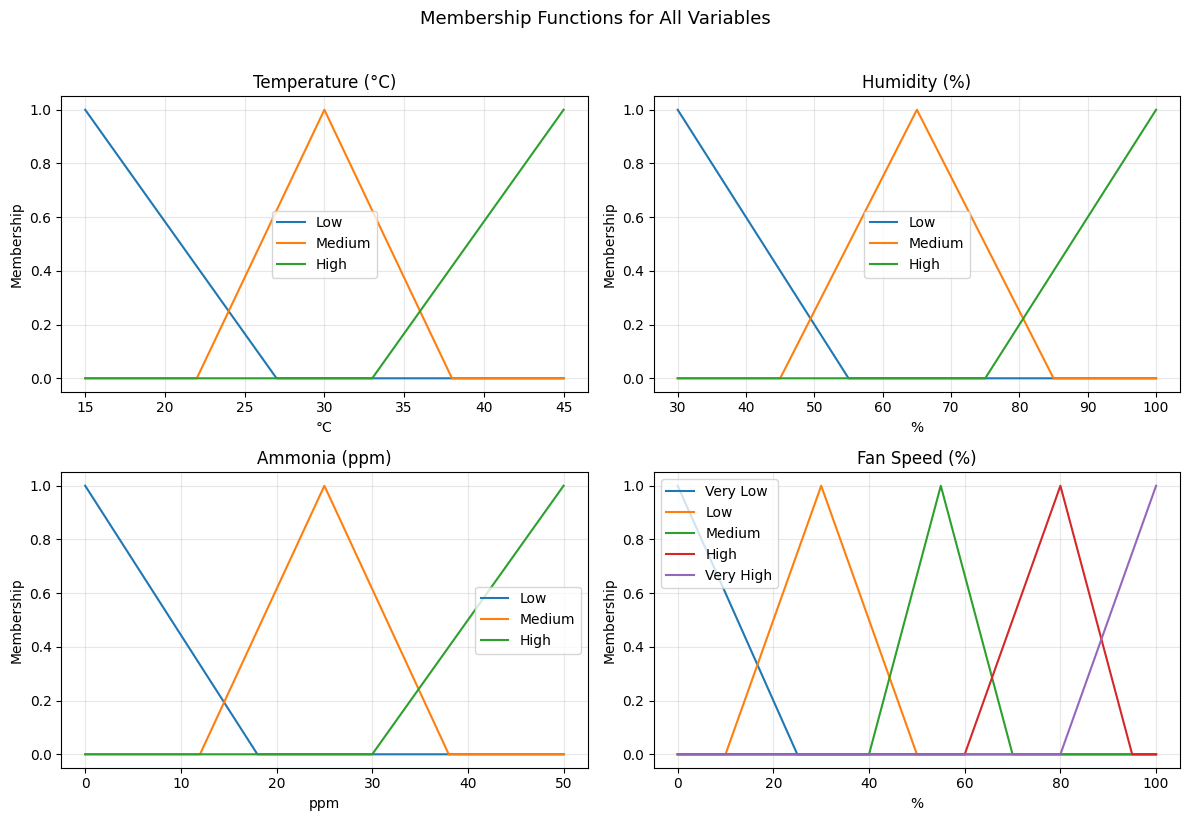

 Temp  Humid   NH3   Fan Speed   Note
   20°C    40%    5ppm      9.35%   Cool & dry, clean air


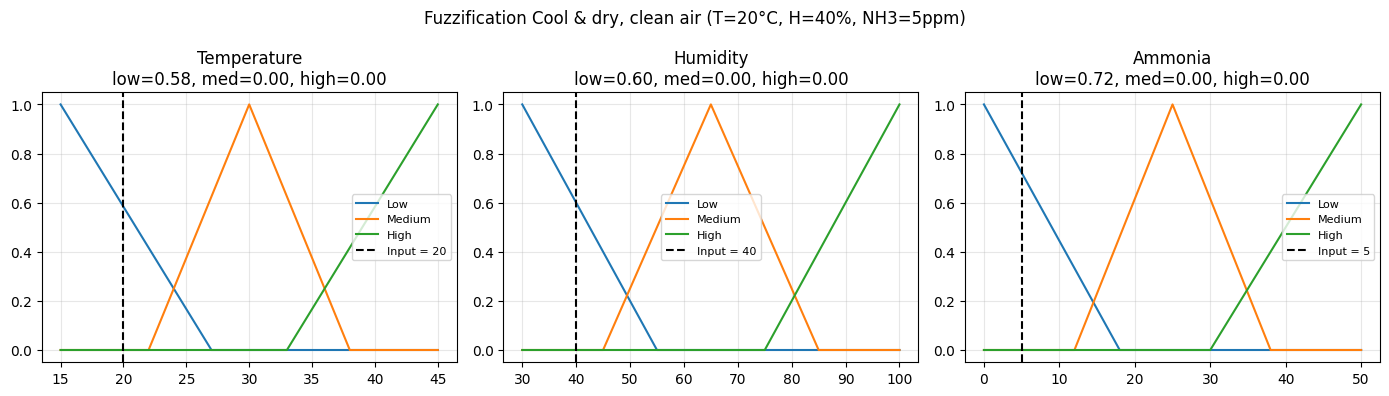

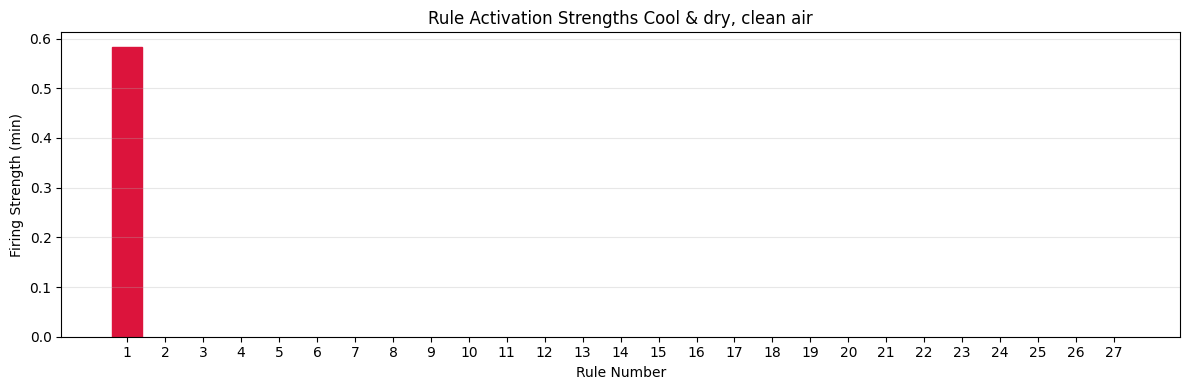

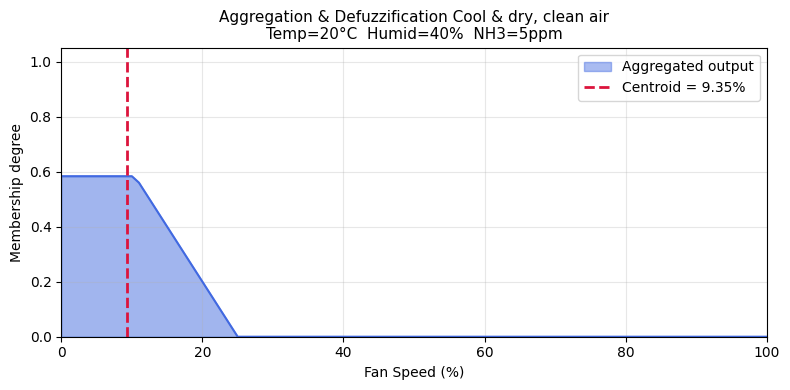

   25°C    65%   25ppm     45.00%   Moderate all-round


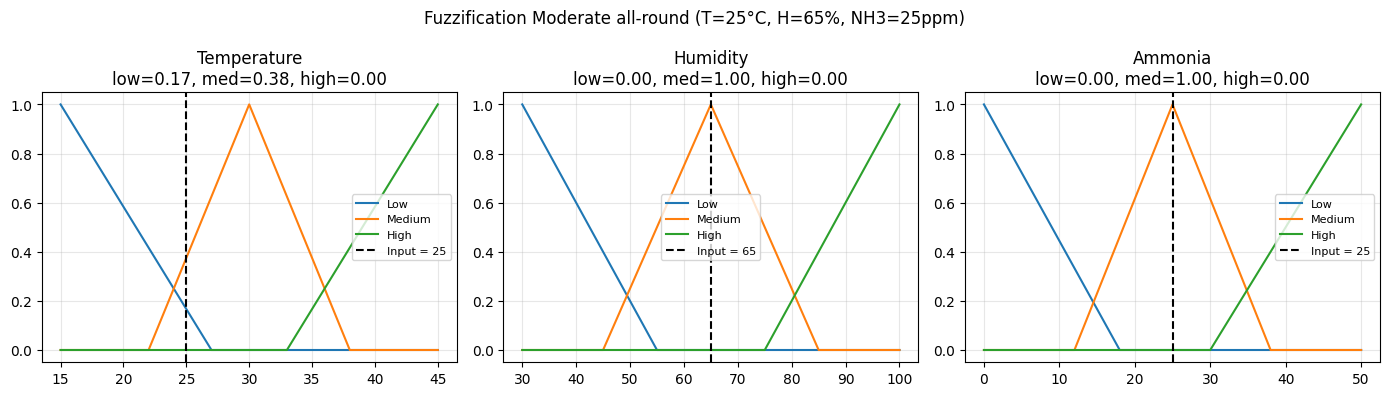

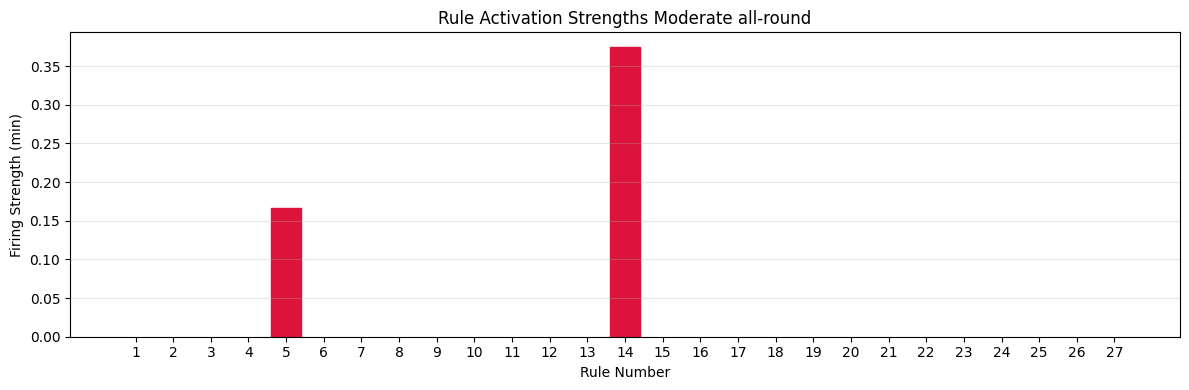

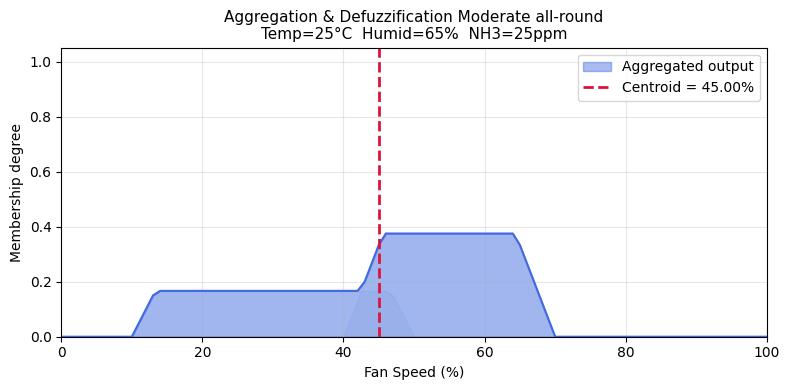

   32°C    80%   35ppm     70.67%   Hot, humid, high NH3


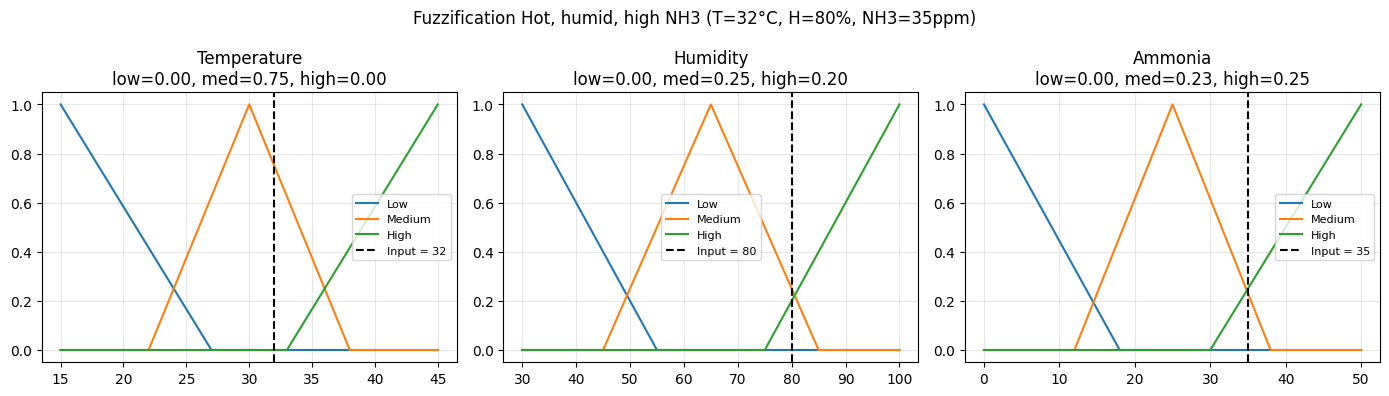

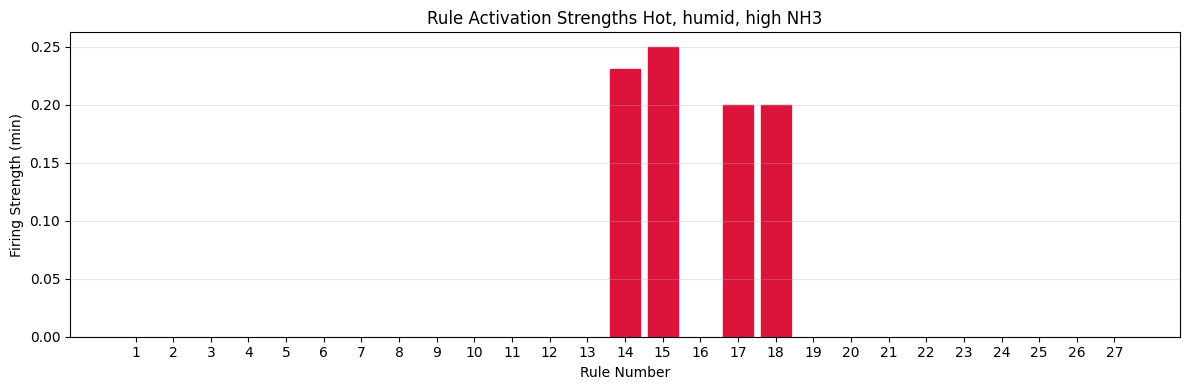

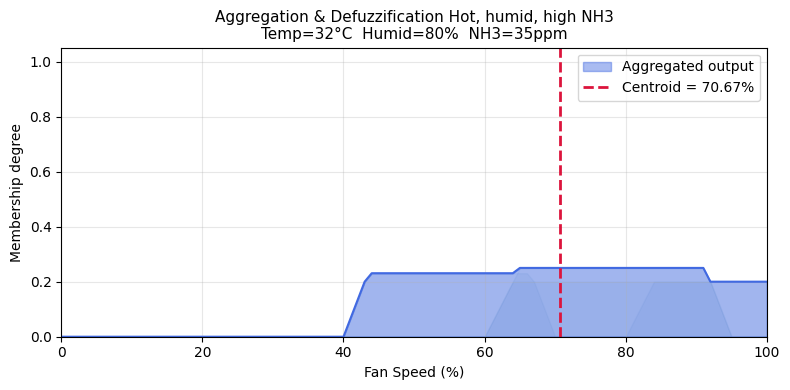

   40°C    90%   45ppm     92.52%   Worst-case scenario


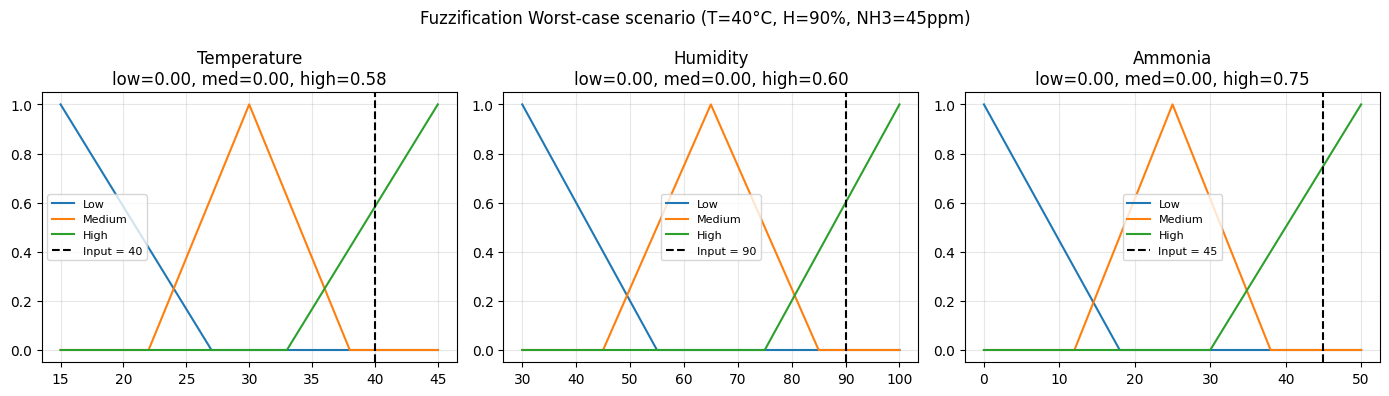

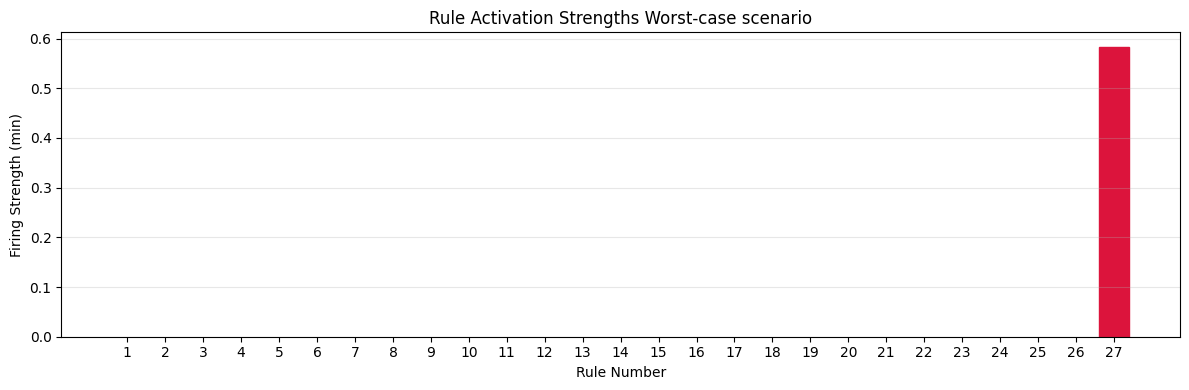

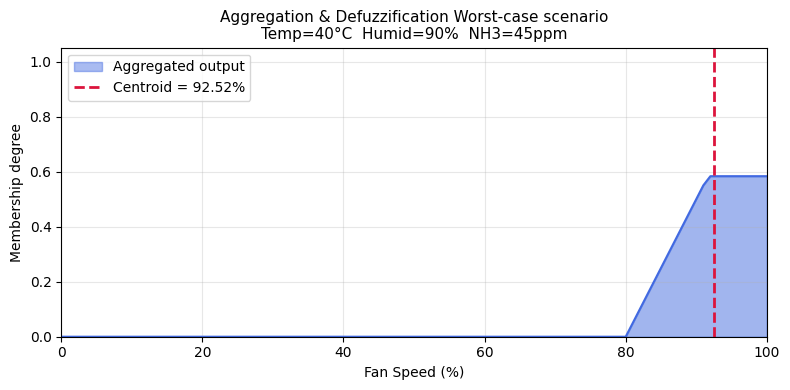

   18°C    75%   42ppm     55.00%   Cool but high ammonia


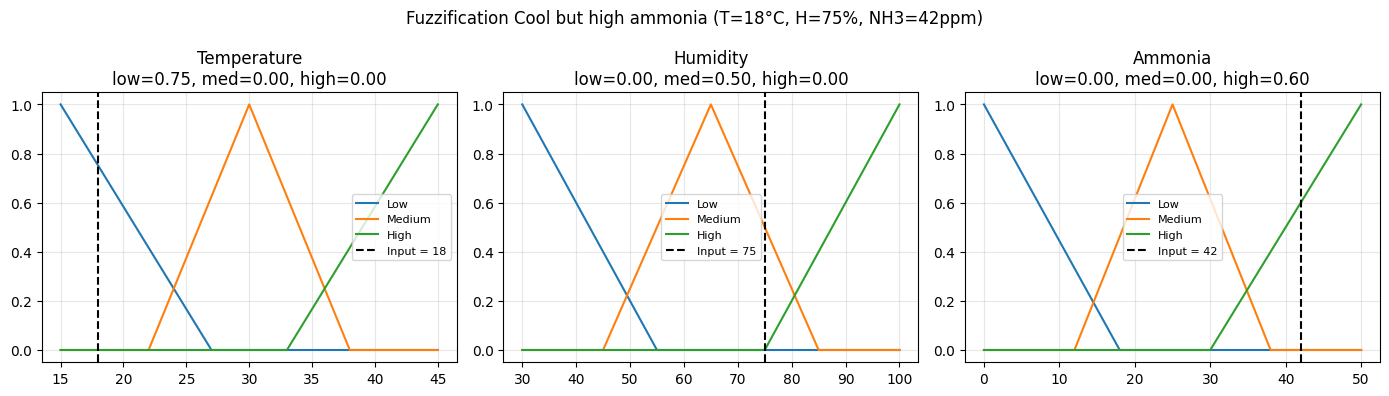

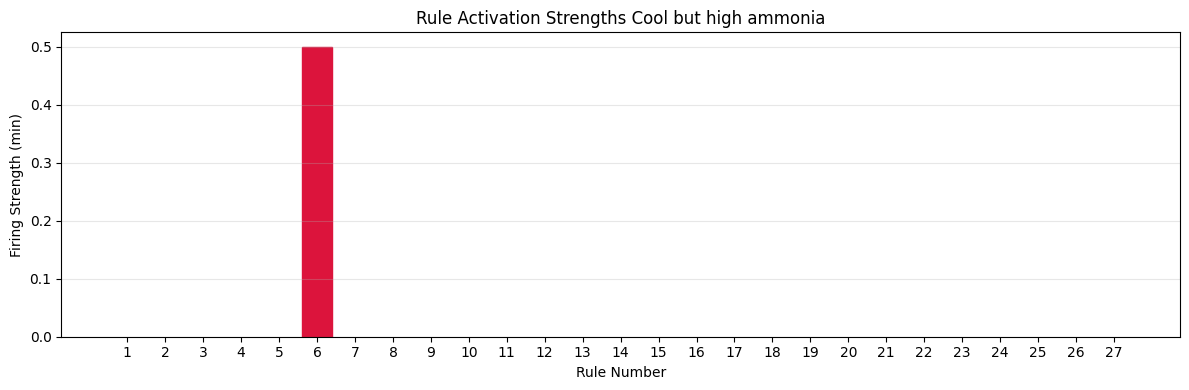

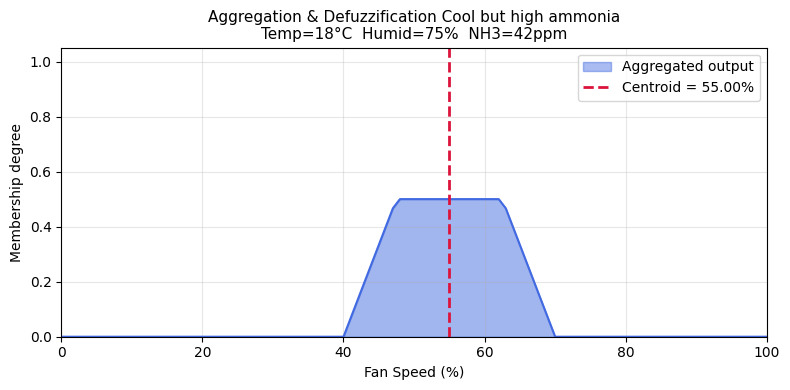

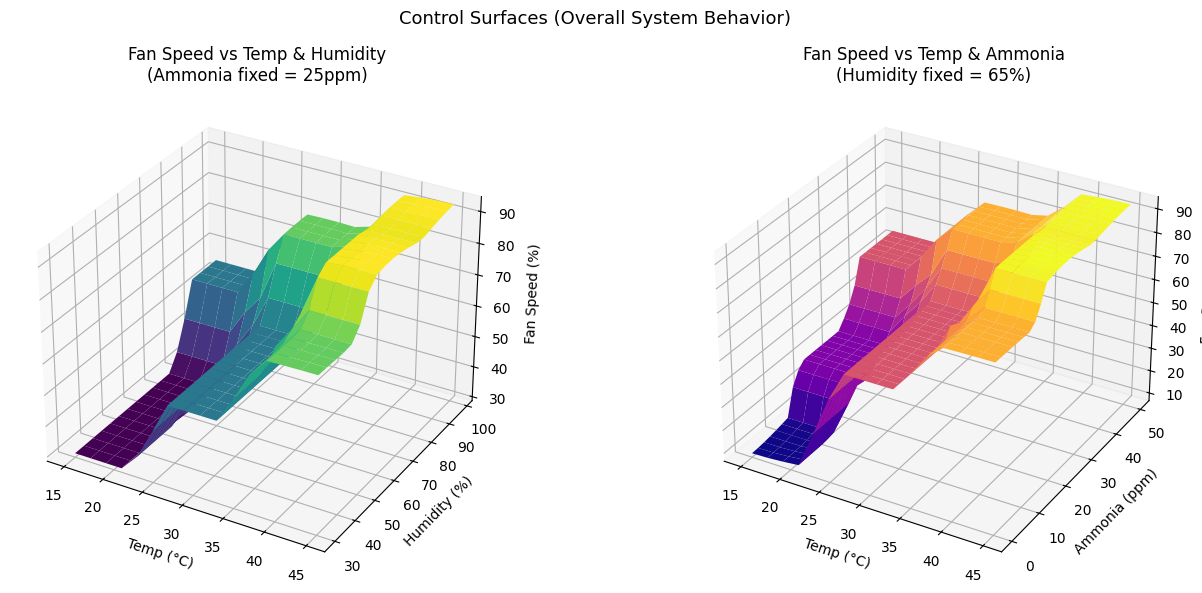

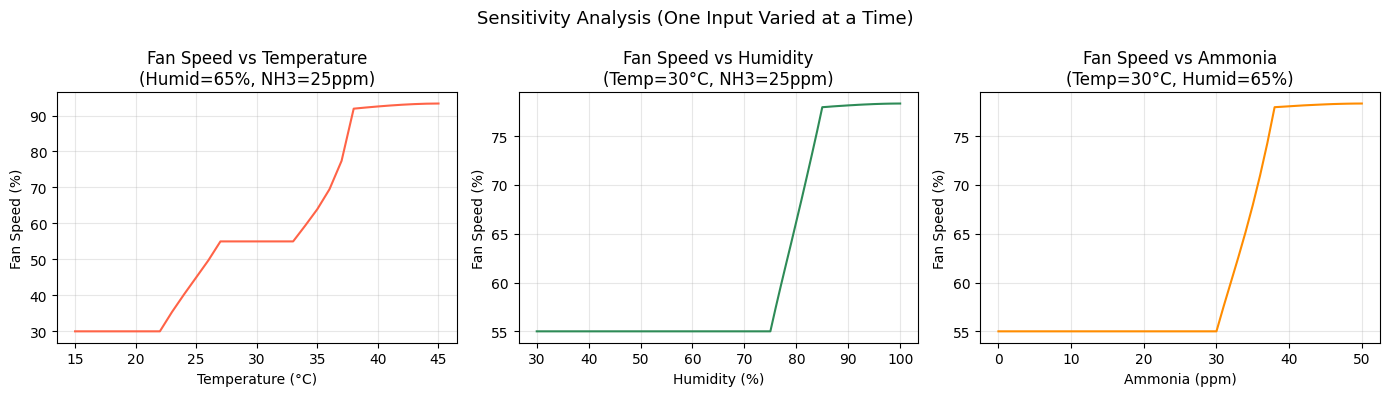

In [19]:
#visualization, surface plot, etc.

# visualization 1 — Membership Functions (all variables)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0, 0].plot(temp_range, temp_low, label='Low')
ax[0, 0].plot(temp_range, temp_medium, label='Medium')
ax[0, 0].plot(temp_range, temp_high, label='High')
ax[0, 0].set_title('Temperature (°C)'); ax[0, 0].set_xlabel('°C')
ax[0, 0].set_ylabel('Membership'); ax[0, 0].legend(); ax[0, 0].grid(alpha=0.3)

ax[0, 1].plot(humid_range, humid_low, label='Low')
ax[0, 1].plot(humid_range, humid_medium, label='Medium')
ax[0, 1].plot(humid_range, humid_high, label='High')
ax[0, 1].set_title('Humidity (%)'); ax[0, 1].set_xlabel('%')
ax[0, 1].set_ylabel('Membership'); ax[0, 1].legend(); ax[0, 1].grid(alpha=0.3)

ax[1, 0].plot(ammonia_range, ammonia_low, label='Low')
ax[1, 0].plot(ammonia_range, ammonia_medium, label='Medium')
ax[1, 0].plot(ammonia_range, ammonia_high, label='High')
ax[1, 0].set_title('Ammonia (ppm)'); ax[1, 0].set_xlabel('ppm')
ax[1, 0].set_ylabel('Membership'); ax[1, 0].legend(); ax[1, 0].grid(alpha=0.3)

ax[1, 1].plot(fan_range, fan_vlow, label='Very Low')
ax[1, 1].plot(fan_range, fan_low, label='Low')
ax[1, 1].plot(fan_range, fan_medium, label='Medium')
ax[1, 1].plot(fan_range, fan_high, label='High')
ax[1, 1].plot(fan_range, fan_vhigh, label='Very High')
ax[1, 1].set_title('Fan Speed (%)'); ax[1, 1].set_xlabel('%')
ax[1, 1].set_ylabel('Membership'); ax[1, 1].legend(); ax[1, 1].grid(alpha=0.3)

plt.suptitle('Membership Functions for All Variables', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


# visualization 2 — Fuzzification (per test case)
def plot_fuzzification(crisp_temp, crisp_humid, crisp_ammonia, mem, tag=""):
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))

    ax[0].plot(temp_range, temp_low, label='Low')
    ax[0].plot(temp_range, temp_medium, label='Medium')
    ax[0].plot(temp_range, temp_high, label='High')
    ax[0].axvline(crisp_temp, color='k', ls='--', label=f'Input = {crisp_temp}')
    ax[0].set_title(f"Temperature\nlow={mem['temp']['low']:.2f}, med={mem['temp']['medium']:.2f}, high={mem['temp']['high']:.2f}")
    ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

    ax[1].plot(humid_range, humid_low, label='Low')
    ax[1].plot(humid_range, humid_medium, label='Medium')
    ax[1].plot(humid_range, humid_high, label='High')
    ax[1].axvline(crisp_humid, color='k', ls='--', label=f'Input = {crisp_humid}')
    ax[1].set_title(f"Humidity\nlow={mem['humid']['low']:.2f}, med={mem['humid']['medium']:.2f}, high={mem['humid']['high']:.2f}")
    ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)

    ax[2].plot(ammonia_range, ammonia_low, label='Low')
    ax[2].plot(ammonia_range, ammonia_medium, label='Medium')
    ax[2].plot(ammonia_range, ammonia_high, label='High')
    ax[2].axvline(crisp_ammonia, color='k', ls='--', label=f'Input = {crisp_ammonia}')
    ax[2].set_title(f"Ammonia\nlow={mem['ammonia']['low']:.2f}, med={mem['ammonia']['medium']:.2f}, high={mem['ammonia']['high']:.2f}")
    ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)

    plt.suptitle(f'Fuzzification {tag} (T={crisp_temp}°C, H={crisp_humid}%, NH3={crisp_ammonia}ppm)', fontsize=12)
    plt.tight_layout()
    plt.show()


# visualization 3 — Rule activation strengths
def plot_rule_activations(rules, tag=""):
    strengths = [r[0] for r in rules]
    fig, ax = plt.subplots(figsize=(12, 4))
    bars = ax.bar(range(1, len(strengths) + 1), strengths, color='steelblue')
    for i, s in enumerate(strengths):
        if s > 0:
            bars[i].set_color('crimson')
    ax.set_xlabel('Rule Number')
    ax.set_ylabel('Firing Strength (min)')
    ax.set_title(f'Rule Activation Strengths {tag}')
    ax.set_xticks(range(1, len(strengths) + 1))
    ax.grid(alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()


# visualization 4 — Aggregation & Defuzzification (centroid)
def plot_aggregation_defuzzification(rules, aggregated, fan_speed, crisp_temp, crisp_humid, crisp_ammonia, tag=""):
    fig, ax = plt.subplots(figsize=(8, 4))

    for strength, mf in rules:
        if strength > 0:
            clipped = np.fmin(strength, mf)
            ax.fill_between(fan_range, 0, clipped, alpha=0.08, color='steelblue')

    ax.fill_between(fan_range, 0, aggregated, alpha=0.45, color='royalblue', label='Aggregated output')
    ax.plot(fan_range, aggregated, color='royalblue', linewidth=1.5)

    ax.axvline(fan_speed, color='crimson', linewidth=2, linestyle='--',
               label=f'Centroid = {fan_speed:.2f}%')

    ax.set_title(f'Aggregation & Defuzzification {tag}\n'
                  f'Temp={crisp_temp}°C  Humid={crisp_humid}%  NH3={crisp_ammonia}ppm', fontsize=11)
    ax.set_xlabel('Fan Speed (%)')
    ax.set_ylabel('Membership degree')
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# testing — test cases with full visualization per case
test_cases = [
    (20, 40, 5,  "Cool & dry, clean air"),
    (25, 65, 25, "Moderate all-round"),
    (32, 80, 35, "Hot, humid, high NH3"),
    (40, 90, 45, "Worst-case scenario"),
    (18, 75, 42, "Cool but high ammonia"),
]

print("=" * 70)
print(f"{'Temp':>5} {'Humid':>6} {'NH3':>5}  {'Fan Speed':>10}   Note")
print("=" * 70)
for temp, humid, ammonia, note in test_cases:
    mem = fuzzify(temp, humid, ammonia)
    rules = apply_rules(mem)
    aggregated = aggregate(rules)
    fan_speed = defuzzify(aggregated)
    print(f"{temp:>5}°C {humid:>5}% {ammonia:>4}ppm {fan_speed:>9.2f}%   {note}")

    plot_fuzzification(temp, humid, ammonia, mem, tag=note)
    plot_rule_activations(rules, tag=note)
    plot_aggregation_defuzzification(rules, aggregated, fan_speed, temp, humid, ammonia, tag=note)
print("=" * 70)


# visualization 5 — Control Surfaces (3D)
fig = plt.figure(figsize=(14, 6))

# Surface 1: Fan speed vs Temp & Humidity (fixed ammonia)
T = np.arange(15, 46, 2)
H = np.arange(30, 101, 4)
TT, HH = np.meshgrid(T, H)
Z1 = np.zeros_like(TT, dtype=float)
fixed_ammonia = 25
for i in range(TT.shape[0]):
    for j in range(TT.shape[1]):
        m = fuzzify(TT[i, j], HH[i, j], fixed_ammonia)
        Z1[i, j] = defuzzify(aggregate(apply_rules(m)))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(TT, HH, Z1, cmap='viridis')
ax1.set_xlabel('Temp (°C)')
ax1.set_ylabel('Humidity (%)')
ax1.set_zlabel('Fan Speed (%)')
ax1.set_title(f'Fan Speed vs Temp & Humidity\n(Ammonia fixed = {fixed_ammonia}ppm)')

# Surface 2: Fan speed vs Temp & Ammonia (fixed humidity)
A = np.arange(0, 51, 2)
TT2, AA = np.meshgrid(T, A)
Z2 = np.zeros_like(TT2, dtype=float)
fixed_humid = 65
for i in range(TT2.shape[0]):
    for j in range(TT2.shape[1]):
        m = fuzzify(TT2[i, j], fixed_humid, AA[i, j])
        Z2[i, j] = defuzzify(aggregate(apply_rules(m)))

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(TT2, AA, Z2, cmap='plasma')
ax2.set_xlabel('Temp (°C)')
ax2.set_ylabel('Ammonia (ppm)')
ax2.set_zlabel('Fan Speed (%)')
ax2.set_title(f'Fan Speed vs Temp & Ammonia\n(Humidity fixed = {fixed_humid}%)')

plt.suptitle('Control Surfaces (Overall System Behavior)', fontsize=13)
plt.tight_layout()
plt.show()


# visualization 6 — Sensitivity Analysis
fixed_humid = 65
fixed_ammonia = 25
fixed_temp = 30

temps = np.arange(15, 46, 1)
fan_vs_temp = []
for t in temps:
    m = fuzzify(t, fixed_humid, fixed_ammonia)
    fan_vs_temp.append(defuzzify(aggregate(apply_rules(m))))

humids = np.arange(30, 101, 1)
fan_vs_humid = []
for h in humids:
    m = fuzzify(fixed_temp, h, fixed_ammonia)
    fan_vs_humid.append(defuzzify(aggregate(apply_rules(m))))

ammonias = np.arange(0, 51, 1)
fan_vs_ammonia = []
for a in ammonias:
    m = fuzzify(fixed_temp, fixed_humid, a)
    fan_vs_ammonia.append(defuzzify(aggregate(apply_rules(m))))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(temps, fan_vs_temp, color='tomato')
ax[0].set_title(f'Fan Speed vs Temperature\n(Humid={fixed_humid}%, NH3={fixed_ammonia}ppm)')
ax[0].set_xlabel('Temperature (°C)'); ax[0].set_ylabel('Fan Speed (%)'); ax[0].grid(alpha=0.3)

ax[1].plot(humids, fan_vs_humid, color='seagreen')
ax[1].set_title(f'Fan Speed vs Humidity\n(Temp={fixed_temp}°C, NH3={fixed_ammonia}ppm)')
ax[1].set_xlabel('Humidity (%)'); ax[1].set_ylabel('Fan Speed (%)'); ax[1].grid(alpha=0.3)

ax[2].plot(ammonias, fan_vs_ammonia, color='darkorange')
ax[2].set_title(f'Fan Speed vs Ammonia\n(Temp={fixed_temp}°C, Humid={fixed_humid}%)')
ax[2].set_xlabel('Ammonia (ppm)'); ax[2].set_ylabel('Fan Speed (%)'); ax[2].grid(alpha=0.3)

plt.suptitle('Sensitivity Analysis (One Input Varied at a Time)', fontsize=13)
plt.tight_layout()
plt.show()

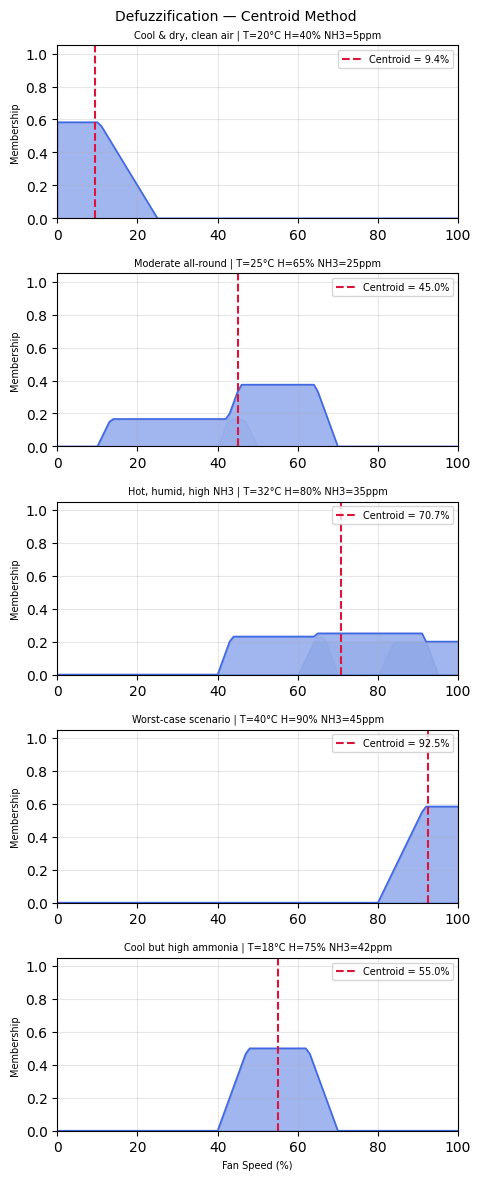

In [20]:
fig, axes = plt.subplots(5, 1, figsize=(5, 12))

test_cases = [
    (20, 40, 5,  "Cool & dry, clean air"),
    (25, 65, 25, "Moderate all-round"),
    (32, 80, 35, "Hot, humid, high NH3"),
    (40, 90, 45, "Worst-case scenario"),
    (18, 75, 42, "Cool but high ammonia"),
]

for idx, (temp, humid, ammonia, note) in enumerate(test_cases):
    mem = fuzzify(temp, humid, ammonia)
    rules = apply_rules(mem)
    aggregated = aggregate(rules)
    fan_speed = defuzzify(aggregated)

    ax = axes[idx]
    for strength, mf in rules:
        if strength > 0:
            clipped = np.fmin(strength, mf)
            ax.fill_between(fan_range, 0, clipped, alpha=0.08, color='steelblue')

    ax.fill_between(fan_range, 0, aggregated, alpha=0.45, color='royalblue')
    ax.plot(fan_range, aggregated, color='royalblue', linewidth=1.2)
    ax.axvline(fan_speed, color='crimson', linewidth=1.5, linestyle='--',
               label=f'Centroid = {fan_speed:.1f}%')
    ax.set_title(f'{note} | T={temp}°C H={humid}% NH3={ammonia}ppm', fontsize=7)
    ax.set_xlim(0, 100); ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(alpha=0.3)
    ax.set_ylabel('Membership', fontsize=7)

axes[-1].set_xlabel('Fan Speed (%)', fontsize=7)
plt.suptitle('Defuzzification — Centroid Method', fontsize=10)
plt.tight_layout()
plt.show()